In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression ,Ridge, Lasso
from sklearn.metrics import mean_squared_error,mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures

In [4]:
df=pd.read_csv('houses_clean.csv')
print(df.head())
print(df.head())
print(df.info())


       area  bedrooms  bathrooms  finishing     floor    price
0 -1.546882 -0.633507  -0.302369   1.259447 -0.302778  2061000
1  0.951989  0.214940  -0.302369  -0.793999 -1.159697  4230000
2  0.508641  1.063387   1.476270  -0.793999 -1.159697  3995000
3 -0.277294 -1.481954  -1.191688   1.259447 -0.302778  2824000
4 -0.297446 -0.633507  -1.191688  -0.793999  1.411060  3079000
       area  bedrooms  bathrooms  finishing     floor    price
0 -1.546882 -0.633507  -0.302369   1.259447 -0.302778  2061000
1  0.951989  0.214940  -0.302369  -0.793999 -1.159697  4230000
2  0.508641  1.063387   1.476270  -0.793999 -1.159697  3995000
3 -0.277294 -1.481954  -1.191688   1.259447 -0.302778  2824000
4 -0.297446 -0.633507  -1.191688  -0.793999  1.411060  3079000
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   area       150 non-null    float64
 1   bedrooms   150 non-null   

In [5]:
X = df.drop(columns=['price'])
y = df['price']

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [6]:
model=LinearRegression()
model.fit(x_train, y_train)
y_pred=model.predict(x_test)

In [7]:
print("\ntrain R2 score:", model.score(x_train, y_train))#to check how well the model fits the training data
print("Test R2 score:", model.score(x_test, y_test))#to check how well the model fits the testing data
print(" MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred,)**0.5)
print("MAE:", mean_absolute_error(y_test, y_pred))


train R2 score: 0.9783717861793761
Test R2 score: 0.9788867757509785
 MSE: 24402154116.17497
RMSE: 156211.88852380912
MAE: 125044.9273114734


In [8]:
print('\n intercept:', model.intercept_)
for name,coef in zip(X.columns, model.coef_):
    print(f"{name}: {round(coef, 2)}")


 intercept: 3448134.734725161
area: 744024.43
bedrooms: 197192.38
bathrooms: 115500.8
finishing: -203832.81
floor: 14238.38


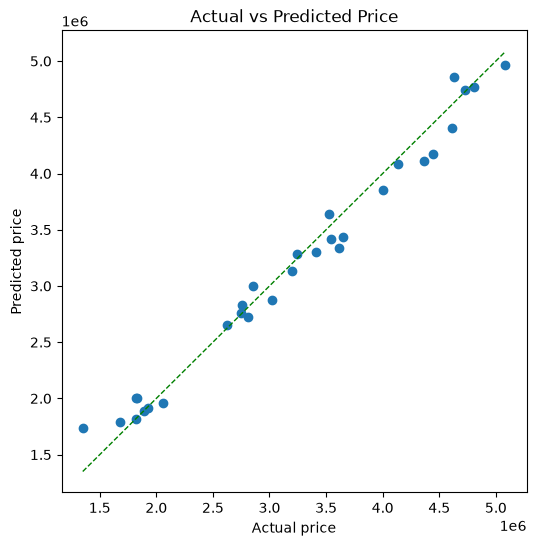

In [9]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], linestyle='--', color='green', lw=1)
plt.xlabel('Actual price')
plt.ylabel('Predicted price')
plt.title('Actual vs Predicted Price')
plt.show()


In [31]:
X_small_train, X_small_test, y_small_train, y_small_test = train_test_split(X, y, test_size=30, random_state=42)
ploy=PolynomialFeatures(degree=5,include_bias=False)
X_small_train_poly=ploy.fit_transform(X_small_train)
X_small_test_poly=ploy.transform(X_small_test)

print("features after polynomial transformation:", X_small_train_poly.shape[1])




features after polynomial transformation: 251


In [32]:
ploy_scaler=StandardScaler()
X_small_train_poly_scaled=ploy_scaler.fit_transform(X_small_train_poly) 
X_small_test_poly_scaled=ploy_scaler.transform(X_small_test_poly)

In [33]:
models = {
    "linear(overfitting)": LinearRegression(),
    "lasso l1": Lasso(alpha=5000, max_iter=1000000),
    "ridge l2": Ridge(alpha=10),
}
train_scores, test_scores = [], []

print("overfitting vs regularization")
print("-" * 55)

for name, m in models.items():
    m.fit(X_small_train_poly_scaled, y_small_train)
    train_r2 = m.score(X_small_train_poly_scaled, y_small_train)
    test_r2 = m.score(X_small_test_poly_scaled, y_small_test)
    train_scores.append(train_r2)
    test_scores.append(test_r2)
    print(f"{name} | Train Score: {train_r2:.4f} | Test Score: {test_r2:.4f}")

overfitting vs regularization
-------------------------------------------------------
linear(overfitting) | Train Score: 0.9995 | Test Score: -4135.9084
lasso l1 | Train Score: 0.9842 | Test Score: 0.9774
ridge l2 | Train Score: 0.9863 | Test Score: 0.9633


In [34]:
lasso_l1= models["lasso l1"]
print ("Lasso: features set ot zero =", (lasso_l1.coef_==0).sum(), "out of", len(lasso_l1.coef_))

Lasso: features set ot zero = 222 out of 251


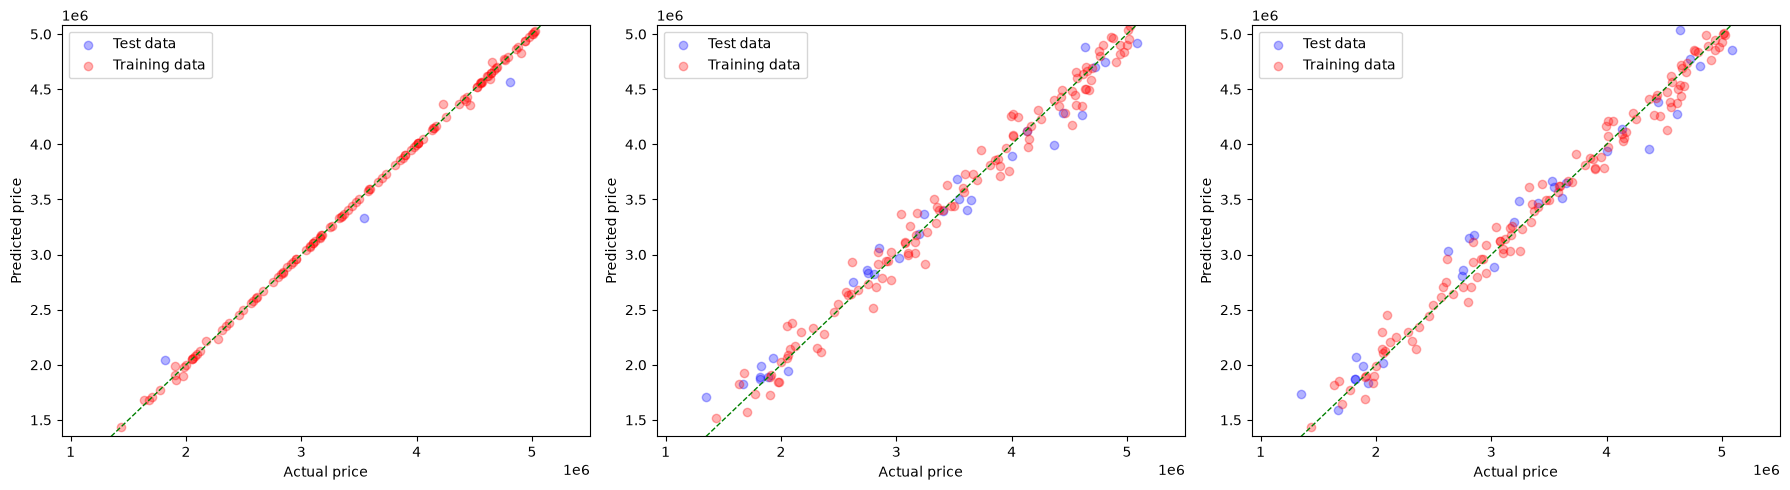

'plt.figure(figsize=(18,5))\n\ni = 1\nfor name, model in models.items():\n    train_pred = model.predict(X_small_train_poly)\n    test_pred= model.predict(X_small_test_poly)\n\n    plt.subplot(1, 3, i)\n    plt.scatter(y_small_train, train_pred, label=\'Test\', alpha=0.5)\n\n    plt.scatter(y_small_test, test_pred, label=\'Train\', alpha= 0.8)\n    plt.plot([y.min(), y.max()],[y.min(),y.max()], "r--")\n    plt.ylim(y.min()*0.5, y.max()*1.5)\n    plt.title(name)\n    plt.xlabel("Actual price")\n    plt.ylabel("Predicted price")\n    plt.legend()\n    i+= 1\n\nplt.tight_layout()\nplt.show()'

In [41]:
plt.figure(figsize=(18, 5)) 

i=1
for name, model in models.items():
    plt.subplot(1,3,i)
    plt.scatter(y_small_test, model.predict(X_small_test_poly_scaled),color='blue', alpha=0.3, label='Test data')
    plt.scatter(y_small_train, model.predict(X_small_train_poly_scaled), color='red', alpha=0.3, label='Training data')
    plt.plot([y_small_test.min(), y_small_test.max()], [y_small_test.min(), y_small_test.max()], linestyle='--', color='green', lw=1)
    plt.ylim(y_small_test.min(), y_small_test.max())
    plt.xlabel('Actual price')
    plt.ylabel('Predicted price')
    plt.legend()
    i+=1


plt.tight_layout()
plt.show()



"""plt.figure(figsize=(18,5))

i = 1
for name, model in models.items():
    train_pred = model.predict(X_small_train_poly)
    test_pred= model.predict(X_small_test_poly)

    plt.subplot(1, 3, i)
    plt.scatter(y_small_train, train_pred, label='Test', alpha=0.5)

    plt.scatter(y_small_test, test_pred, label='Train', alpha= 0.8)
    plt.plot([y.min(), y.max()],[y.min(),y.max()], "r--")
    plt.ylim(y.min()*0.5, y.max()*1.5)
    plt.title(name)
    plt.xlabel("Actual price")
    plt.ylabel("Predicted price")
    plt.legend()
    i+= 1

plt.tight_layout()
plt.show()"""
